# Employee Attrition Analysis & Prediction
**Goal:** Understand why employees leave and build a model that flags employees at risk of leaving, so HR can act early.

**Data:** HRDataset_v14.csv, a public synthetic HR dataset (311 employees, 36 columns). `Termd` = 1 if the employee left.

**Approach:** data cleaning → EDA (SQL-style questions answered in pandas) → modelling with proper validation → business recommendations.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
df = pd.read_csv('HRDataset_v14.csv')
print(df.shape)
df.head(3)

(311, 36)


,Employee_Name,EmpID,MarriedID,MaritalStatusID,GenderID,EmpStatusID,DeptID,PerfScoreID,FromDiversityJobFairID,Salary,...,ManagerName,ManagerID,RecruitmentSource,PerformanceScore,EngagementSurvey,EmpSatisfaction,SpecialProjectsCount,LastPerformanceReview_Date,DaysLateLast30,Absences
0,"Adinolfi, Wilson K",10026,0,0,1,1,5,4,0,62506,...,Michael Albert,22.0,LinkedIn,Exceeds,4.60,5,0,1/17/2019,0,1
1,"Ait Sidi, Karthikeyan",10084,1,1,1,5,3,3,0,104437,...,Simon Roup,4.0,Indeed,Fully Meets,4.96,3,6,2/24/2016,0,17
2,"Akinkuolie, Sarah",10196,1,1,0,5,5,3,0,64955,...,Kissy Sullivan,20.0,LinkedIn,Fully Meets,3.02,3,0,5/15/2012,0,3


## 1. Data cleaning & quality checks

In [2]:
# Whitespace in categorical text (e.g. 'Production       ')
for c in ['Department','Position','ManagerName','RecruitmentSource','PerformanceScore']:
    df[c] = df[c].str.strip()

df['DateofHire'] = pd.to_datetime(df['DateofHire'])
df['DateofTermination'] = pd.to_datetime(df['DateofTermination'])

print('Duplicate employees:', df['EmpID'].duplicated().sum())
print('Missing values:'); print(df.isna().sum()[df.isna().sum()>0])
print('\nAttrition rate: {:.1%}  ({} of {})'.format(df.Termd.mean(), df.Termd.sum(), len(df)))
df.EmploymentStatus.value_counts()

Duplicate employees: 0
Missing values:
DateofTermination    207
ManagerID              8
dtype: int64

Attrition rate: 33.4%  (104 of 311)


EmploymentStatus
Active                    207
Voluntarily Terminated     88
Terminated for Cause       16
Name: count, dtype: int64

**Notes:** `DateofTermination` is empty for active employees (expected, not an error). 8 rows have no `ManagerID`, which I don't use. **Attrition is 33.4%**, so accuracy alone would be misleading: always predicting "stays" scores 66.6%. I therefore evaluate with ROC-AUC, precision and recall.

## 2. Exploratory analysis: who leaves?

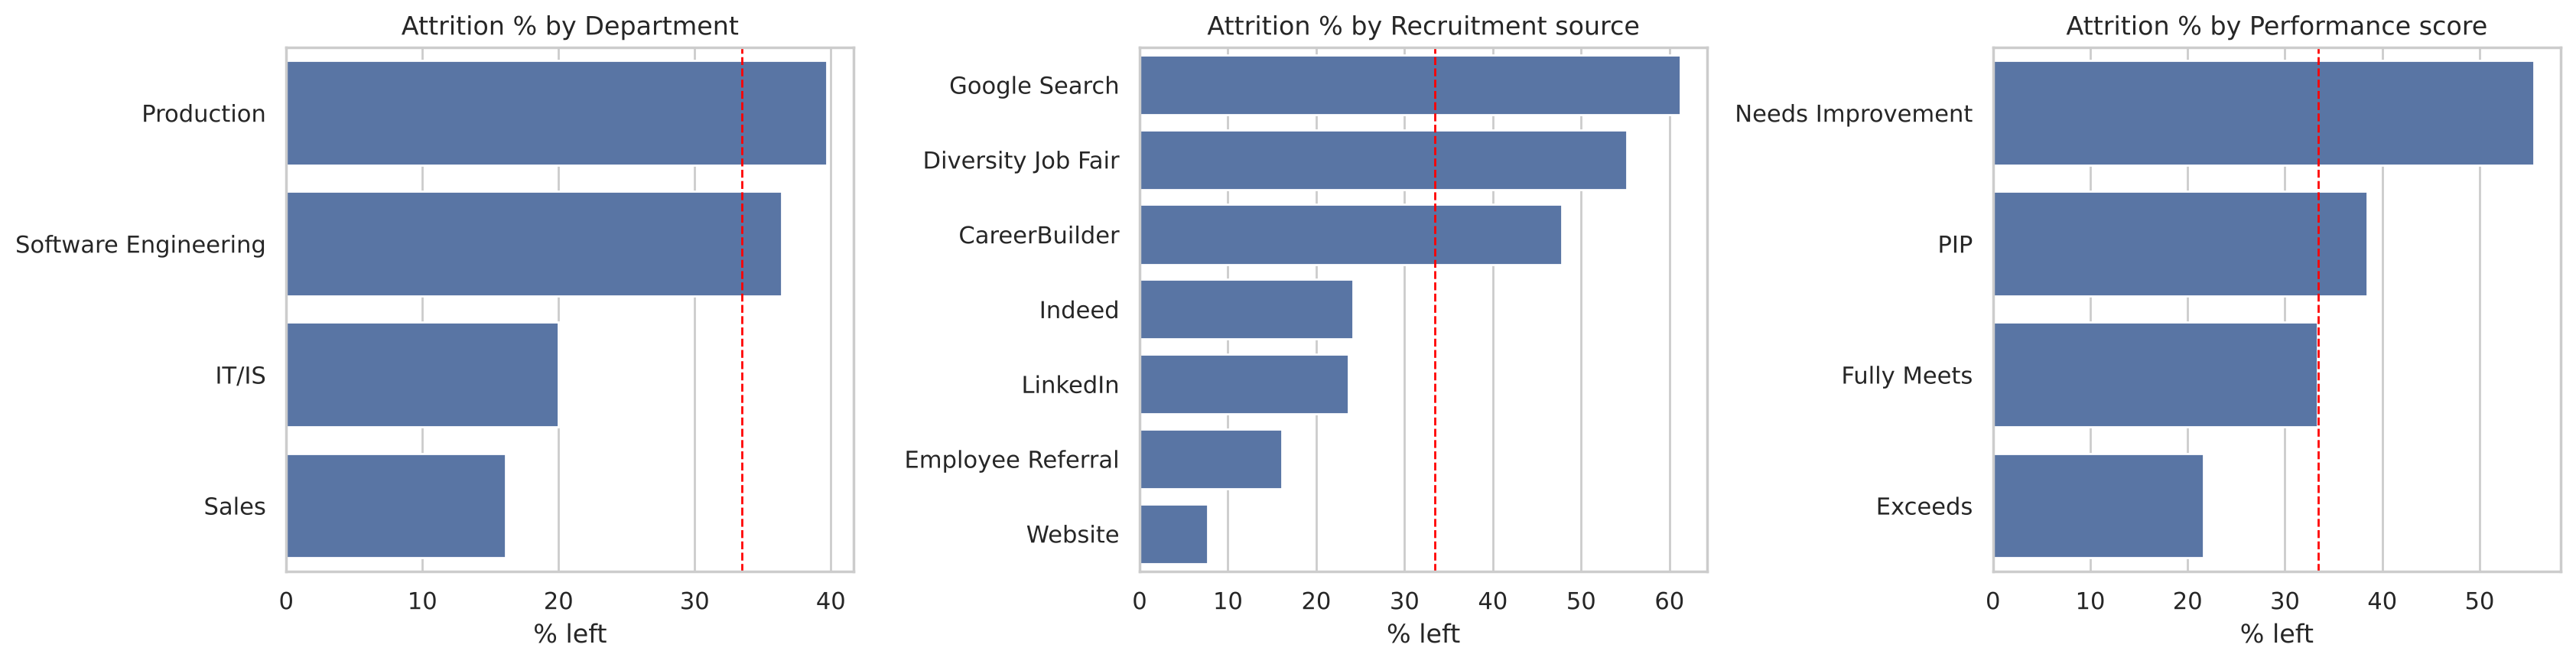

(                      attrition  headcount
 Department                                
 Production             0.397129        209
 Software Engineering   0.363636         11
 IT/IS                  0.200000         50
 Sales                  0.161290         31,
                     attrition  headcount
 RecruitmentSource                       
 Google Search        0.612245         49
 Diversity Job Fair   0.551724         29
 CareerBuilder        0.478261         23
 Indeed               0.241379         87
 LinkedIn             0.236842         76
 Employee Referral    0.161290         31
 Website              0.076923         13)

In [3]:
def rate(col, min_n=10):
    t = df.groupby(col)['Termd'].agg(attrition='mean', headcount='count')
    return t[t.headcount>=min_n].sort_values('attrition', ascending=False)

fig, ax = plt.subplots(1, 3, figsize=(17,4.5))
for a,(col,title) in zip(ax,[('Department','Department'),('RecruitmentSource','Recruitment source'),('PerformanceScore','Performance score')]):
    t = rate(col)
    sns.barplot(x=t.attrition*100, y=t.index, ax=a, color='#4C72B0')
    a.axvline(df.Termd.mean()*100, color='red', ls='--', lw=1)
    a.set_title(f'Attrition % by {title}'); a.set_xlabel('% left'); a.set_ylabel('')
plt.tight_layout(); plt.show()
rate('Department'), rate('RecruitmentSource')

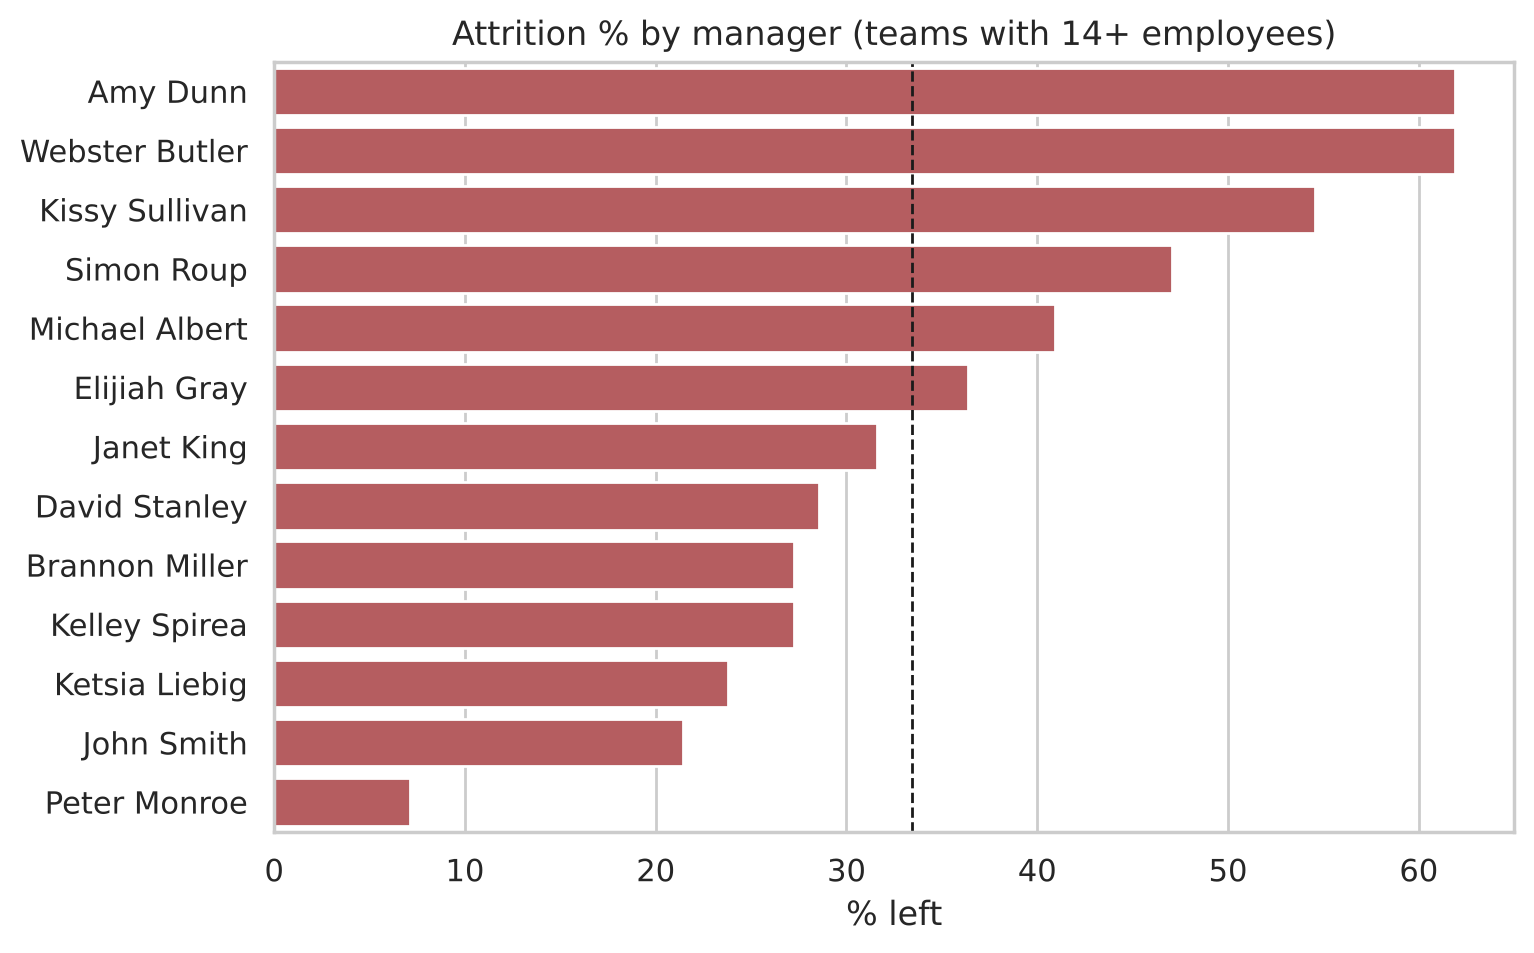

In [4]:
mgr = rate('ManagerName', min_n=14)
plt.figure(figsize=(8,5))
sns.barplot(x=mgr.attrition*100, y=mgr.index, color='#C44E52')
plt.axvline(df.Termd.mean()*100, color='k', ls='--', lw=1)
plt.title('Attrition % by manager (teams with 14+ employees)'); plt.xlabel('% left'); plt.ylabel('')
plt.show()

          Salary  EngagementSurvey  EmpSatisfaction  SpecialProjectsCount  \
Termd                                                                       
Stayed  70694.03              4.12             3.89                  1.46   
Left    65690.08              4.09             3.88                  0.73   

        DaysLateLast30  Absences  TenureYears  
Termd                                          
Stayed            0.29      9.83         5.51  
Left              0.66     11.05         3.46  


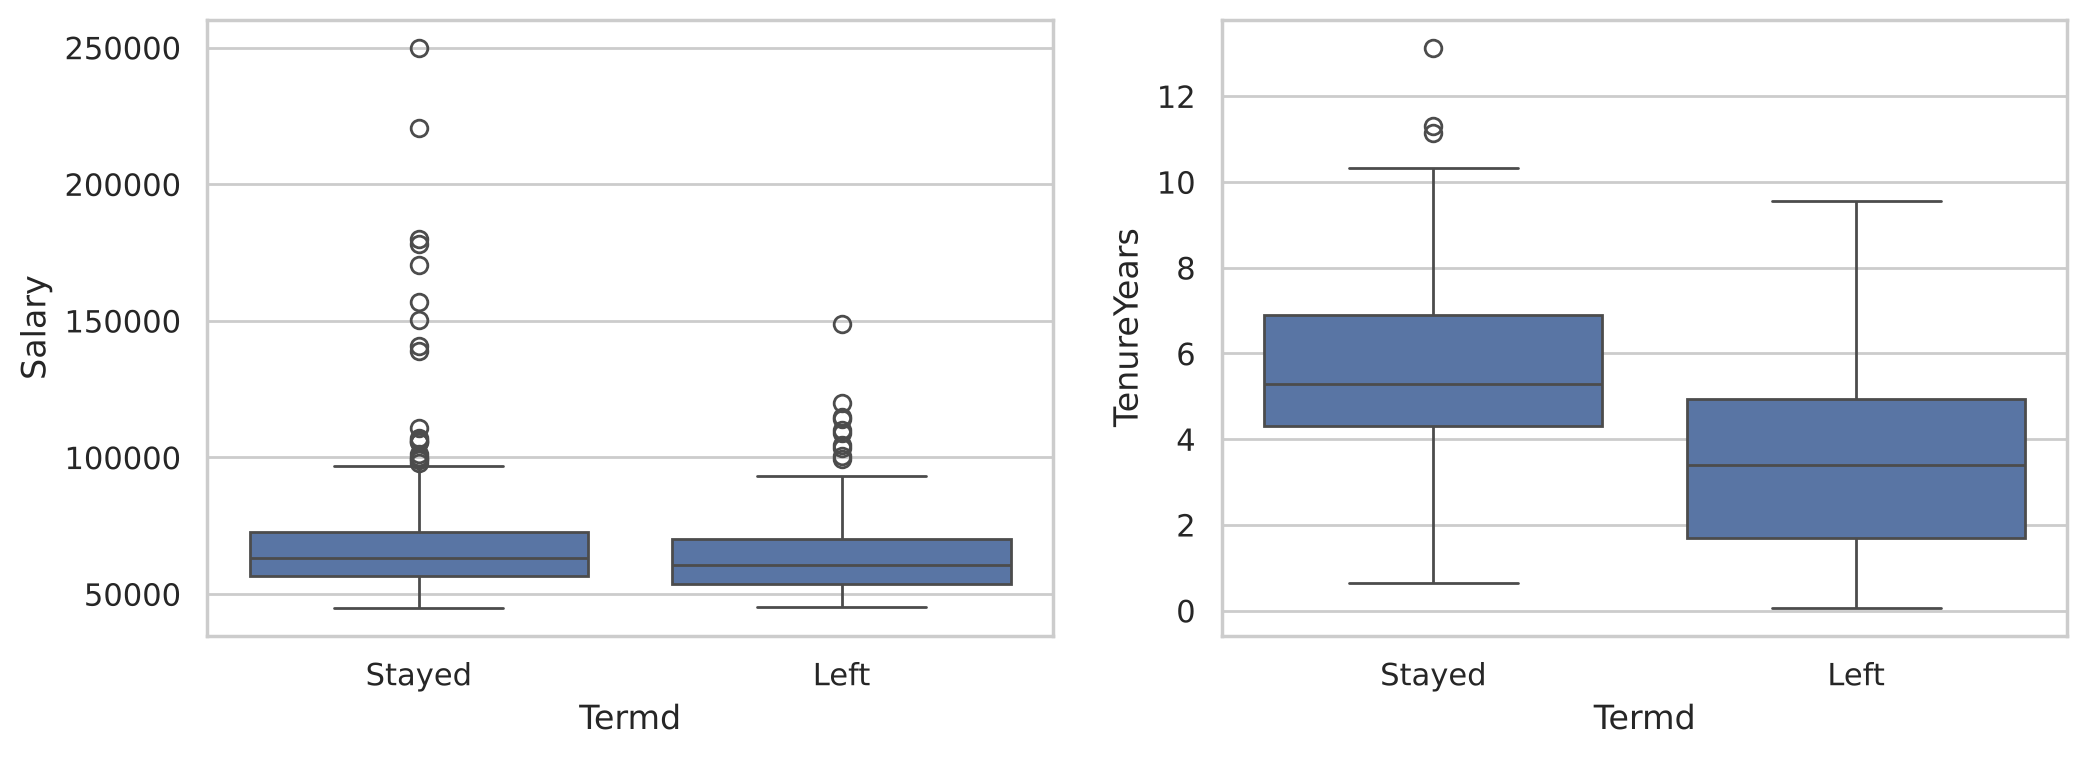

In [5]:
end = pd.Timestamp('2019-02-28')   # latest review date in the data = 'as of' date for active staff
df['TenureYears'] = ((df.DateofTermination.fillna(end) - df.DateofHire).dt.days/365.25)

print(df.groupby('Termd')[['Salary','EngagementSurvey','EmpSatisfaction','SpecialProjectsCount','DaysLateLast30','Absences','TenureYears']].mean().round(2).rename(index={0:'Stayed',1:'Left'}))

fig, ax = plt.subplots(1,2, figsize=(12,4))
sns.boxplot(data=df, x='Termd', y='Salary', ax=ax[0]); ax[0].set_xticklabels(['Stayed','Left'])
sns.boxplot(data=df, x='Termd', y='TenureYears', ax=ax[1]); ax[1].set_xticklabels(['Stayed','Left'])
plt.show()

In [6]:
# Do leavers give reasons? (voluntary + for-cause exits only)
reasons = df[df.Termd==1]['TermReason'].value_counts()
reasons.head(8)

TermReason
Another position          20
unhappy                   14
more money                11
career change              9
hours                      8
attendance                 7
return to school           5
relocation out of area     5
Name: count, dtype: int64

### EDA takeaways
1. **Production drives attrition**: 40% of Production employees left vs 16% in Sales and 20% in IT/IS. Production is also 67% of headcount, so it accounts for most leavers.
2. **Recruitment source matters**: hires from Google Search (61%), Diversity Job Fair (55%) and CareerBuilder (48%) leave far more than Employee Referrals (16%) or the company Website (8%). Many of the weakest channels are the ones with the most volume.
3. **Manager effect is large**: attrition ranges from ~7% to ~62% across managers with similar-sized teams. This is the strongest actionable signal.
4. **Performance**: employees rated *Needs Improvement* leave at 56% and *PIP* at 38%, versus 22% for *Exceeds*.
5. **Engagement score and satisfaction barely differ** between leavers and stayers (4.09 vs 4.12; 3.88 vs 3.89), so surveys are not a useful early-warning signal here. Leavers earned ~$5k less on average, worked on half as many special projects (0.73 vs 1.46), and were late more often (0.66 vs 0.29 days).
6. Leavers had shorter tenure (median ~3.4 yrs vs ~5.3 for those still employed), but tenure is *determined by* the exit date, so I **don't use it as a model feature** (it would leak the answer).

## 3. Predictive model
**Leakage control:** I exclude `EmploymentStatus`, `TermReason`, `DateofTermination`, `EmpStatusID` and `TenureYears` (they encode the outcome). I also exclude gender, race, marital status, citizenship and age: using protected characteristics to score employees would be unethical and legally risky.

In [7]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay

num = ['Salary','EngagementSurvey','EmpSatisfaction','SpecialProjectsCount','DaysLateLast30','Absences']
cat = ['Department','RecruitmentSource','PerformanceScore','ManagerName']
X, y = df[num+cat], df['Termd']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

pre = ColumnTransformer([('num', StandardScaler(), num),
                         ('cat', OneHotEncoder(handle_unknown='ignore'), cat)])   # imputing/scaling happen inside the pipeline: no leakage
models = {
 'Baseline (always "stays")': DummyClassifier(strategy='most_frequent'),
 'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
 'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight='balanced', random_state=42),
 'Gradient Boosting': GradientBoostingClassifier(random_state=42),
}
cv = StratifiedKFold(5, shuffle=True, random_state=42)
rows = []
for name, m in models.items():
    r = cross_validate(Pipeline([('pre',pre),('m',m)]), X_train, y_train, cv=cv,
                       scoring=['accuracy','precision','recall','f1','roc_auc'])
    rows.append({'model':name, **{k.replace('test_',''):v.mean() for k,v in r.items() if k.startswith('test_')}})
cv_res = pd.DataFrame(rows).set_index('model').round(3)
cv_res

,accuracy,precision,recall,f1,roc_auc
model,,,,,
"Baseline (always ""stays"")",0.665,0.000,0.000,0.000,0.500
Logistic Regression,0.652,0.499,0.654,0.561,0.704
Random Forest,0.665,0.511,0.567,0.530,0.704
Gradient Boosting,0.665,0.504,0.423,0.458,0.691


5-fold stratified cross-validation on the training set. The baseline gets ~67% accuracy but **0 recall**, which is why accuracy is not the headline metric. Logistic Regression and Random Forest tie on ROC-AUC (~0.70); I pick the best by ROC-AUC and prefer Logistic Regression for its recall on leavers and interpretability.

**Honest read:** ROC-AUC ~0.70 is *modest*. The model ranks leavers above stayers better than chance, but it is not accurate enough to make individual decisions. With only 311 rows, that is expected.

Best model: Logistic Regression
              precision    recall  f1-score   support

      Stayed       0.79      0.63      0.70        52
        Left       0.47      0.65      0.55        26

    accuracy                           0.64        78
   macro avg       0.63      0.64      0.63        78
weighted avg       0.68      0.64      0.65        78

Test ROC-AUC: 0.675


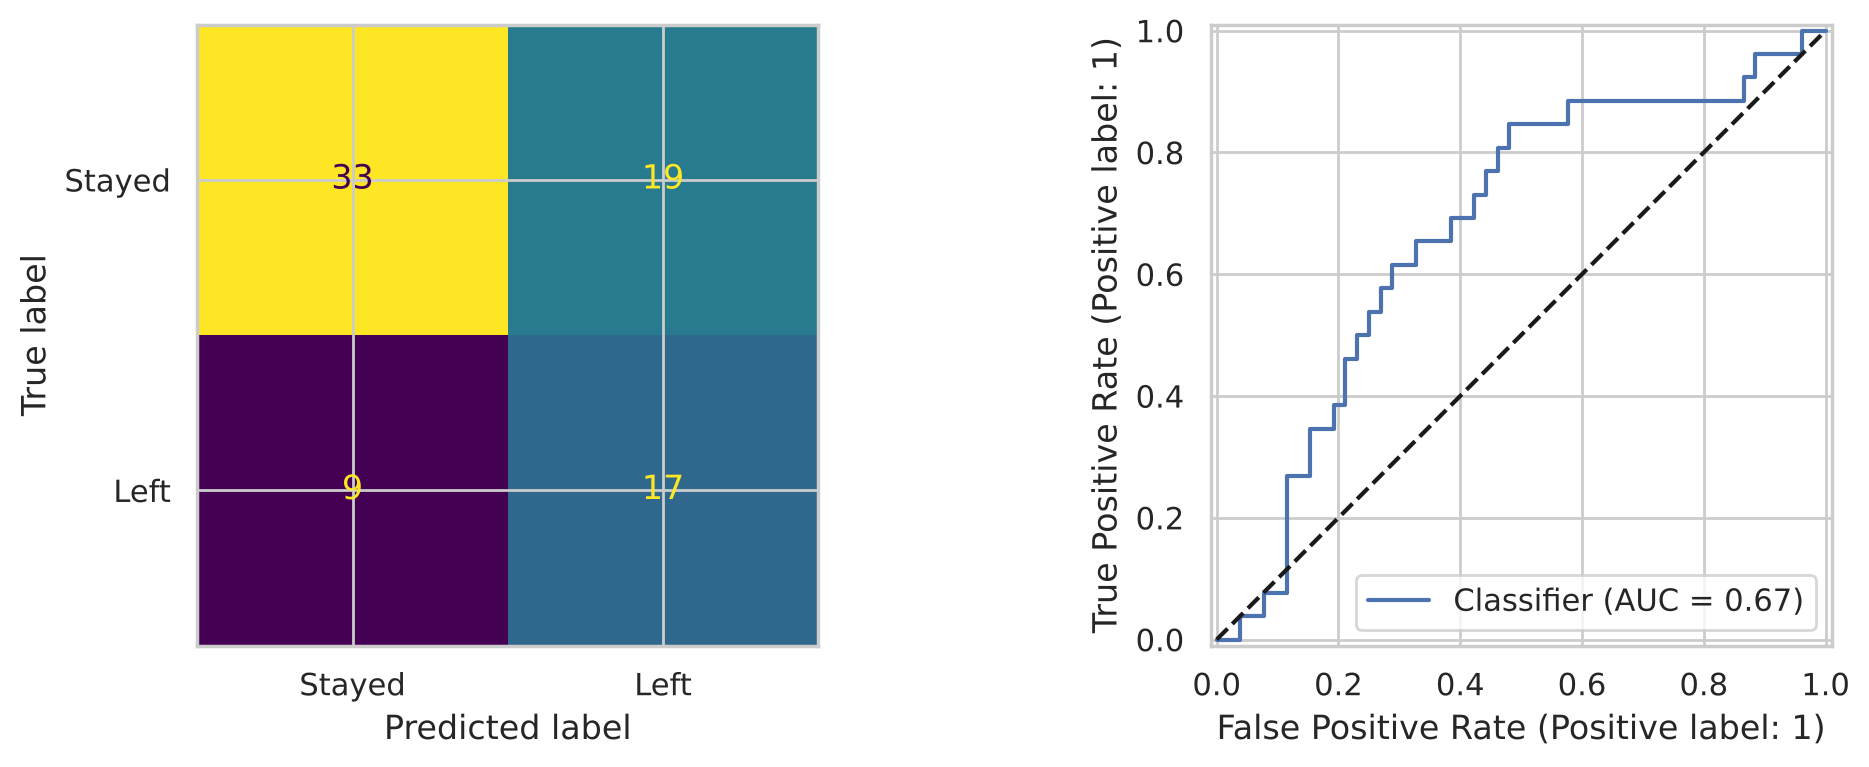

In [8]:
best_name = cv_res.drop(index='Baseline (always "stays")')['roc_auc'].idxmax()
print('Best model:', best_name)
best = Pipeline([('pre',pre),('m',models[best_name])]).fit(X_train, y_train)
pred = best.predict(X_test); proba = best.predict_proba(X_test)[:,1]
print(classification_report(y_test, pred, target_names=['Stayed','Left']))
print('Test ROC-AUC: {:.3f}'.format(roc_auc_score(y_test, proba)))

fig, ax = plt.subplots(1,2, figsize=(11,4))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['Stayed','Left'], ax=ax[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, proba, ax=ax[1]); ax[1].plot([0,1],[0,1],'k--')
plt.tight_layout(); plt.show()

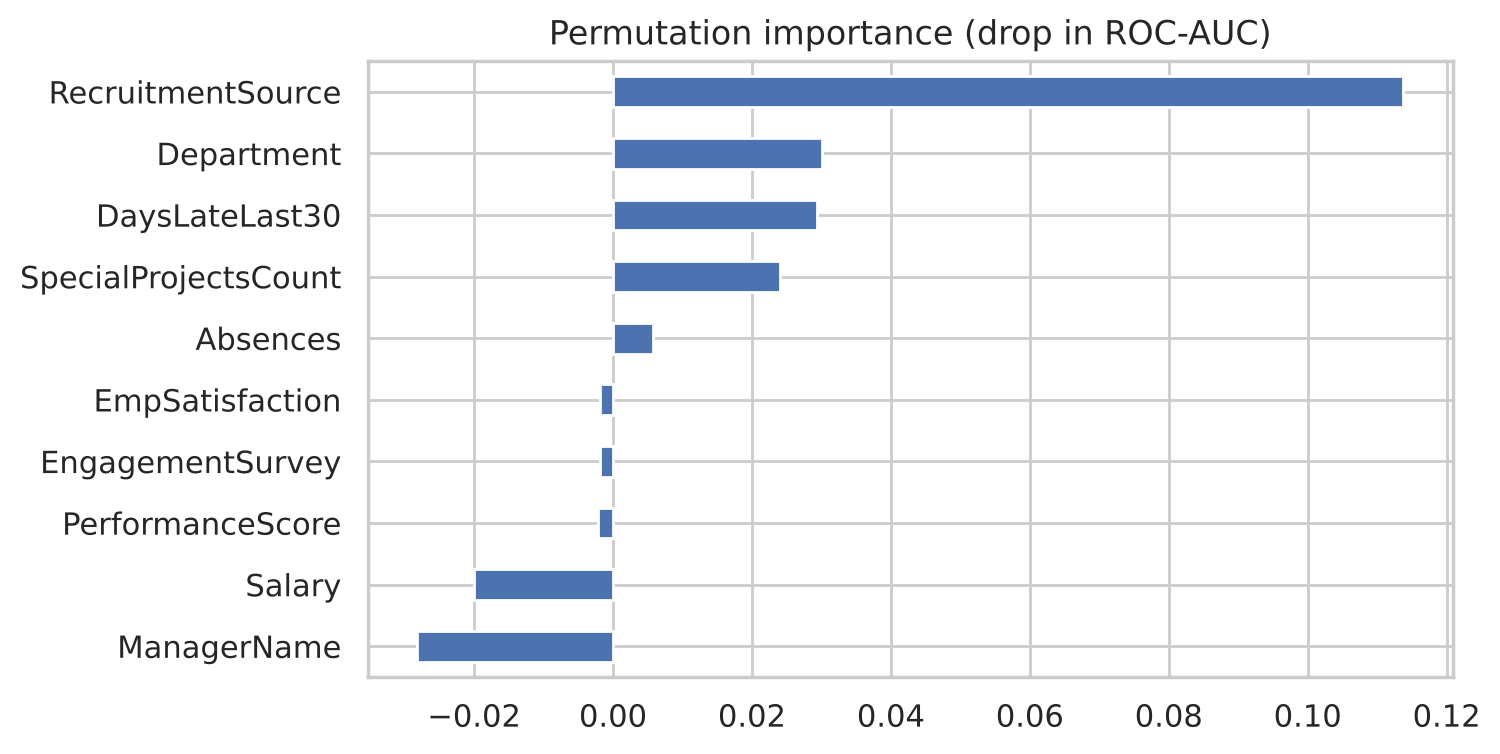

RecruitmentSource       0.114
Department              0.030
DaysLateLast30          0.029
SpecialProjectsCount    0.024
Absences                0.006
EmpSatisfaction        -0.002
EngagementSurvey       -0.002
PerformanceScore       -0.002
Salary                 -0.020
ManagerName            -0.028
dtype: float64

In [9]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(best, X_test, y_test, n_repeats=30, random_state=42, scoring='roc_auc')
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values()
imp.plot.barh(figsize=(7,4), color='#4C72B0'); plt.title('Permutation importance (drop in ROC-AUC)'); plt.show()
imp.sort_values(ascending=False).round(3)

## 4. Limitations (read before trusting the numbers)
- **Small dataset (311 rows, ~78 in the test set)**: metrics have wide error bars; a different split can move them several points.
- **Synthetic data**: patterns may not reflect a real company.
- Engagement/satisfaction scores may have been recorded close to the exit date, so they are weak proxies.
- **Test-set accuracy (~64%) is slightly below the always-"stays" baseline (66.5%)**; the model's value is in recall for leavers (~65%), at the cost of many false alarms (precision ~47%).
- Manager shows large differences in the EDA, but has *negative* permutation importance in the model: with 21 managers and ~15 people each, one-hot encoding overfits. The EDA finding stands as a descriptive signal, to be investigated, not used to blame individuals.
- The top model signal is recruitment source, followed by department, lateness and special projects. Treat these as hypotheses to test, not causes.

## 5. Business recommendations
1. **Audit the manager effect**: review teams with 50%+ attrition (exit interviews, workload, pay) before the next hiring round.
2. **Shift recruiting spend** toward Employee Referrals and the company website; review ROI of Google Search and CareerBuilder hires.
3. **Focus retention on Production**, the largest and highest-attrition department (pay review, career path from Technician I → II).
4. **Collect more data before deploying any model** (more employees, timestamped survey data, exit interviews). Until then, rely on the descriptive findings above rather than individual-level predictions.